# Benchmark: Premier League 2015/16

Verdelingen van 10 maatstaven per team per wedstrijd (760 rijen). Dit zijn de doelen waartegen de simulatie later wordt vergeleken (zie PRD, succesmaatstaven).

Bron: StatsBomb open data. Bij publicatie bronvermelding met logo verplicht. Coordinaten van StatsBomb zijn in yards; lengtes zijn hier omgerekend naar meters.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
t = pd.read_csv('../data/pl_1516_team_match.csv')
t.shape

(760, 13)

## Samenvatting
Gemiddelde, spreiding en het 10e / 50e / 90e percentiel. Het 10e–90e bereik is het venster waar de simulatie binnen moet vallen.

In [2]:
cols = ['goals','shots','xg','xg_per_shot','passes','pass_accuracy','pass_length_m','possession_share','ppda','ppda_pressure']
summary = t[cols].describe(percentiles=[.1,.5,.9]).loc[['mean','std','10%','50%','90%']].round(2).T
summary

,mean,std,10%,50%,90%
goals,1.30,1.20,0.00,1.00,3.00
shots,13.04,5.26,7.00,12.00,20.00
xg,1.28,0.73,0.46,1.15,2.26
xg_per_shot,0.10,0.04,0.05,0.09,0.16
passes,485.02,107.60,347.00,476.50,625.00
pass_accuracy,0.75,0.07,0.66,0.76,0.83
pass_length_m,20.38,1.80,18.23,20.22,22.85
possession_share,0.50,0.10,0.36,0.50,0.64
ppda,13.33,5.06,8.32,12.34,19.50
ppda_pressure,3.13,1.03,2.03,2.93,4.48


## Verdelingen

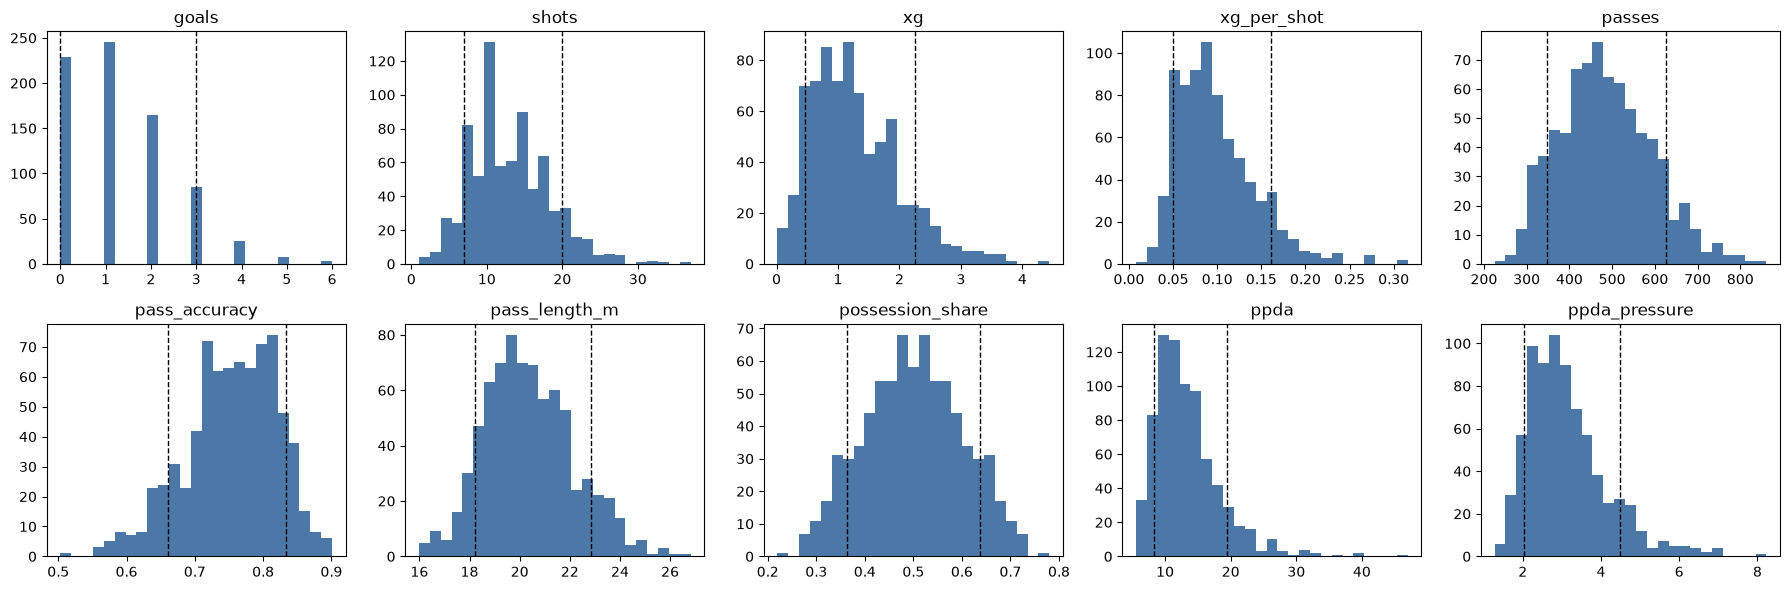

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, c in zip(axes.flat, cols):
    ax.hist(t[c].dropna(), bins=25, color='#4c78a8')
    p10, p90 = t[c].quantile([.1, .9])
    ax.axvline(p10, color='k', ls='--', lw=1); ax.axvline(p90, color='k', ls='--', lw=1)
    ax.set_title(c)
plt.tight_layout(); plt.show()

## Sanity checks
- Doelpunten: 988 in de data tegen 1026 in het echte seizoen; het verschil (38) zijn eigen doelpunten, die hier niet zijn meegeteld.
- Teamverschillen in pressing (PPDA): lage waarde = veel druk.

In [4]:
t.groupby('team')[['ppda','ppda_pressure','possession_share','pass_length_m']].mean().round(2).sort_values('ppda')

,ppda,ppda_pressure,possession_share,pass_length_m
team,,,,
Liverpool,10.36,2.36,0.56,19.00
Tottenham Hotspur,10.36,2.40,0.56,20.17
Manchester United,10.64,2.70,0.58,19.49
Chelsea,11.40,2.82,0.55,18.66
Manchester City,11.47,2.85,0.57,18.23
Crystal Palace,12.21,2.98,0.47,21.90
Arsenal,12.21,3.03,0.58,18.39
Southampton,12.44,2.96,0.49,20.70
West Ham United,13.29,3.46,0.49,20.85


## Open punten
- PPDA is een eigen definitie (tackles, interceptions, overtredingen, verloren duels); vastleggen in WP9.
- Dit is profvoetbal in de Premier League; voor amateurniveaus bestaat geen kalibratiedata.
- Data wordt nog niet gebruikt in het product; licentie zie vault, `Licenties en Steam`.